# Artificial Intelligence

* Md. Jalil Piran
* Sejong University
* piran@sejong.ac.kr

# Constraint Satisfaction Problems

* Three main examples: Australia map coloring, N-Queens, and cryptarithmetic.
* Each example applies;
  * Exhaustive enumeration,
  * Backtracking,
  * MRV,
  * Degree Heuristic,
  * LCV,
  * Forward checking,
  * AC-3,
  * MAC,
  * min-conflicts,
  * Tree solver after cycle-cutset conditioning.

## Shared CSP model, definitions and algorithms
* A finite-domain CSP contains variables X, domains D, and constraints C.
* A solution assigns every variable and satisfies every constraint.
* A consistent partial assignment may still have no complete extension.
* All three examples use a shared binary engine.


### Algorithm
```text
Declare variables and their domains.
Declare edges and a compatibility predicate.
Check candidate assignments against the original model.
```


In [ ]:
from collections import deque
from itertools import product, combinations, permutations
from time import perf_counter
import random
import numpy as np
import matplotlib.pyplot as plt

class BinaryCSP:
    def __init__(self, domains, edges, compatible):
        self.variables = list(domains)
        self.domains = {x: list(dict.fromkeys(v)) for x, v in domains.items()}
        self.neighbors = {x: [] for x in domains}
        for x, y in edges:
            if x == y or x not in domains or y not in domains:
                raise ValueError("Edges must join distinct declared variables")
            if y not in self.neighbors[x]: self.neighbors[x].append(y)
            if x not in self.neighbors[y]: self.neighbors[y].append(x)
        self.compatible = compatible
    def valid(self, a):
        return (set(a) == set(self.variables)
                and all(a[x] in self.domains[x] for x in self.variables)
                and all(self.compatible(x, a[x], y, a[y])
                        for x in self.variables for y in self.neighbors[x]))

def not_equal(x, a, y, b): return a != b

def copy_domains(csp): return {x: v[:] for x, v in csp.domains.items()}


* Domains have independent lists. Every search branch receives fresh copies.
* Neighbors are stored in both directions; asymmetric predicates must express the same relation when arguments reverse.
* `valid` verifies original domains and all binary restrictions.

## Shared AC-3 and forward checking
* Forward checking removes incompatible values from unassigned neighbors of a decision.
* AC-3 repeatedly removes a tail value if the head domain has no support for it.
* When a tail domain changes, reconsider incoming arcs from other neighbors.
* Both return False on domain wipeout. True means no wipeout was detected, not necessarily that a solution exists.

### Algorithm
```text
FORWARD CHECK: filter unassigned neighbors after one decision.
AC3: queue arcs; revise tail domains; requeue affected incoming arcs.
```


In [ ]:
def forward_check(csp, x, a, assignment, domains, stats=None):
    for y in csp.neighbors[x]:
        if y not in assignment:
            before = len(domains[y])
            domains[y] = [b for b in domains[y] if csp.compatible(x, a, y, b)]
            if stats is not None: stats["pruned"] += before - len(domains[y])
            if not domains[y]: return False
    return True

def ac3(csp, domains, queue=None, stats=None):
    q = deque(queue if queue is not None else
              [(x, y) for x in csp.variables for y in csp.neighbors[x]])
    if any(not v for v in domains.values()): return False
    while q:
        x, y = q.popleft()
        kept = [a for a in domains[x]
                if any(csp.compatible(x, a, y, b) for b in domains[y])]
        if len(kept) != len(domains[x]):
            if stats is not None: stats["pruned"] += len(domains[x]) - len(kept)
            domains[x] = kept
            if not kept: return False
            q.extend((z, x) for z in csp.neighbors[x] if z != y)
    return True


### Filtering
* The pruning counter compares domain size before and after deletion.



## Shared backtracking and ordering
* Select the next variable in insertion order, or choose MRV.
* Optionally break MRV ties by degree; optionally order values by LCV.
* Choose no inference, forward checking, or MAC.
* Initially MAC enforces AC-3 on all arcs. Each later decision propagates incoming arcs into the selected variable.
* Return one solution. Undo failed assignments; domain copies restore earlier choices automatically.

### Algorithm
```text
If complete, return assignment.
Select a variable by fixed order or MRV with optional degree.
Try legal values in domain order or LCV order.
Copy domains, assign a singleton, and optionally propagate.
Recurse if no domain is empty; undo the decision on failure.
```


In [ ]:
def solve(csp, inference="none", mrv=False, degree=False, lcv=False, trace=False):
    if inference not in {"none", "fc", "mac"}: raise ValueError("Unknown inference")
    stats = dict(calls=0, attempts=0, backtracks=0, pruned=0)
    assignment, events = {}, []
    def legal(x, d):
        return [a for a in d[x] if all(csp.compatible(x,a,y,assignment[y])
                for y in csp.neighbors[x] if y in assignment)]
    def visit(d):
        stats["calls"] += 1
        if len(assignment) == len(csp.variables): return assignment.copy()
        free = [x for x in csp.variables if x not in assignment]
        if mrv:
            x = min(free, key=lambda v: (len(legal(v,d)),
                    -sum(y not in assignment for y in csp.neighbors[v]) if degree else 0))
        elif degree:
            x = max(free, key=lambda v: sum(y not in assignment for y in csp.neighbors[v]))
        else: x = free[0]
        values = legal(x,d)
        if lcv:
            values.sort(key=lambda a: sum(not csp.compatible(x,a,y,b)
                for y in csp.neighbors[x] if y not in assignment for b in legal(y,d)))
        for a in values:
            stats["attempts"] += 1
            assignment[x] = a
            if trace: events.append(("assign", x, a))
            child = {v: vals[:] for v,vals in d.items()}; child[x] = [a]
            ok = True
            if inference == "fc": ok = forward_check(csp,x,a,assignment,child,stats)
            if inference == "mac": ok = ac3(csp,child,[(y,x) for y in csp.neighbors[x]],stats)
            result = visit(child) if ok else None
            if result is not None: return result
            if trace: events.append(("undo", x, a))
            del assignment[x]
        stats["backtracks"] += 1
        return None
    domains = copy_domains(csp)
    ok = all(domains.values())
    if ok and inference == "mac": ok = ac3(csp,domains,stats=stats)
    answer = visit(domains) if ok else None
    return answer, stats, events

CONFIGS = [
    ("Backtracking", {}),
    ("MRV", dict(mrv=True)),
    ("MRV + degree", dict(mrv=True,degree=True)),
    ("MRV + degree + LCV", dict(mrv=True,degree=True,lcv=True)),
    ("Forward checking", dict(inference="fc",mrv=True,degree=True,lcv=True)),
    ("MAC", dict(inference="mac",mrv=True,degree=True,lcv=True))
]

def run_method(csp, label, **options):
    start = perf_counter()
    answer, stats, events = solve(csp, **options)
    elapsed = 1000*(perf_counter()-start)
    assert answer is None or csp.valid(answer)
    print(label, "solution:", answer)
    print("Statistics:", stats, "milliseconds:", round(elapsed,3))
    return answer, stats, events


* `calls`: recursive search entries;
* `attempts`: legal candidates assigned;
* `backtracks`: search calls that exhaust their candidates;
* `pruned`: propagation deletions across explored branches.


## Shared exhaustive enumeration and local repair
* Enumeration below is used only when the complete Cartesian product is small enough.
* Min-conflicts starts with a complete assignment. It chooses a conflicted variable, then a minimum-conflict value.
* Random ties and restarts improve exploration. A failed budget is not an infeasibility proof.

### Algorithm
```text
ENUMERATE: generate complete assignments; retain independently valid ones.
MIN CONFLICTS: random complete assignment; repair a conflicted variable;
repeat or restart; stop at a valid assignment or exhausted budget.
```


In [ ]:
def enumerate_csp(csp):
    checked, solutions = 0, []
    for values in product(*(csp.domains[x] for x in csp.variables)):
        checked += 1
        a = dict(zip(csp.variables,values))
        if csp.valid(a): solutions.append(a)
    return solutions, checked

def min_conflicts(csp, seed=42, max_steps=2000, restarts=20):
    rng = random.Random(seed); history = []
    if any(not d for d in csp.domains.values()): return None, history
    def conflicts(x,a,state):
        return sum(not csp.compatible(x,a,y,state[y]) for y in csp.neighbors[x])
    for restart in range(restarts):
        state = {x:rng.choice(csp.domains[x]) for x in csp.variables}
        for step in range(max_steps+1):
            scores = {x:conflicts(x,state[x],state) for x in csp.variables}
            history.append(sum(scores.values())//2)
            bad = [x for x in csp.variables if scores[x]]
            if not bad: return state.copy(), history
            if step == max_steps: break
            x = rng.choice(bad)
            costs = [conflicts(x,a,state) for a in csp.domains[x]]
            low = min(costs)
            state[x] = rng.choice([a for a,c in zip(csp.domains[x],costs) if c==low])
    return None, history


### Enumeration and repair
* Generic enumeration includes auxiliary variables when present. Cryptarithmetic enumeration instead uses original letter variables, then extends them uniquely to the auxiliary tuple.
* `history` records conflicting unordered edges. Jumps may occur at restart boundaries.

## Shared tree solver and cycle-cutset conditioning
* None of the three full models is a tree. Deleting constraints to make one would change the problem.
* Instead fix a cycle cutset, filter residual domains, and solve each remaining tree component. This preserves the original restrictions.
* For a tree, revise parents against children in reverse order, then select supported values from root to leaves.
* Tree solving is O(nd²) for maximum domain size d and constant-time binary checks. Cutset enumeration adds an exponential factor in cutset size.

### Algorithm
```text
Enumerate consistent cutset assignments.
Remove fixed variables and filter residual domains against them.
Verify the residual graph is a forest.
Solve every tree component; combine and validate the full assignment.
```


In [ ]:
def forest_components(csp, variables):
    remaining = set(variables); components = []
    for root in csp.variables:
        if root not in remaining: continue
        parent = {root:None}; order = [root]; remaining.remove(root)
        for x in order:
            for y in csp.neighbors[x]:
                if y not in variables or y == parent[x]: continue
                if y in parent: raise ValueError("Residual graph is not a forest")
                parent[y] = x; order.append(y); remaining.remove(y)
        components.append((parent,order))
    return components

def tree_solve(csp):
    if not csp.variables: return {}
    components = forest_components(csp,set(csp.variables))
    if len(components)!=1: raise ValueError("Expected one connected tree")
    parent,order = components[0]; d = copy_domains(csp)
    if any(not v for v in d.values()): return None
    for y in reversed(order[1:]):
        x = parent[y]
        d[x] = [a for a in d[x] if any(csp.compatible(x,a,y,b) for b in d[y])]
        if not d[x]: return None
    result = {order[0]:d[order[0]][0]}
    for y in order[1:]:
        x = parent[y]
        result[y] = next(b for b in d[y] if csp.compatible(x,result[x],y,b))
    return result

def cutset_solve(csp, cutset):
    residual = set(csp.variables)-set(cutset)
    components = forest_components(csp,residual)
    trials = 0
    for vals in product(*(csp.domains[x] for x in cutset)):
        trials += 1; fixed = dict(zip(cutset,vals))
        if any(not csp.compatible(x,fixed[x],y,fixed[y])
               for x in cutset for y in csp.neighbors[x] if y in fixed): continue
        result = fixed.copy(); feasible = True
        for _,order in components:
            domains = {x:[a for a in csp.domains[x] if all(csp.compatible(x,a,y,fixed[y])
                       for y in csp.neighbors[x] if y in fixed)] for x in order}
            links = [(x,y) for x in order for y in csp.neighbors[x]
                     if y in domains and csp.variables.index(x)<csp.variables.index(y)]
            sub = BinaryCSP(domains,links,csp.compatible)
            tail = tree_solve(sub)
            if tail is None: feasible=False; break
            result.update(tail)
        if feasible:
            assert csp.valid(result)
            return result,trials
    return None,trials


### Structural reduction
* Isolated vertices are one-variable tree components.
* Cutset conditioning remains complete on finite domains but can be costly. A dense N-Queens graph needs a large cutset.
* The residual forest check prevents accidental application of the tree theorem to cyclic graphs.


## 1 Australia map coloring
* Variables: WA, NT, SA, Q, NSW, V, T.
* Domain: Red, Green, Blue.
* Constraint: adjacent regions have different colors.
* There are 3⁷ = 2,187 unconstrained assignments and 18 valid assignments.
* The mainland triangle has 3 × 2 × 1 = 6 colorings; its remaining colors are forced. Tasmania independently contributes a factor of 3.

### Algorithm
```text
Create the map model; draw its graph; use the same model in each method.
```


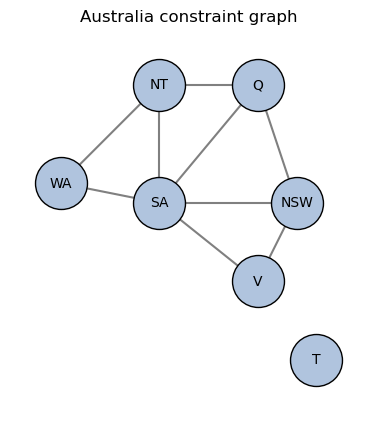

In [ ]:
states = {"WA":["NT","SA"],"NT":["WA","SA","Q"],
          "SA":["WA","NT","Q","NSW","V"],"Q":["NT","SA","NSW"],
          "NSW":["Q","SA","V"],"V":["SA","NSW"],"T":[]}
colors = ["Red","Green","Blue"]
map_edges = sorted({tuple(sorted((x,y))) for x,ns in states.items() for y in ns})
map_csp = BinaryCSP({x:colors for x in states},map_edges,not_equal)
positions = {"WA":(0,1),"NT":(1,2),"SA":(1,.8),"Q":(2,2),
             "NSW":(2.4,.8),"V":(2,0),"T":(2.6,-.8)}
def draw_map(answer=None, title="Australia constraint graph"):
    fig,ax=plt.subplots(figsize=(7,5))
    for x,y in map_edges:
        ax.plot([positions[x][0],positions[y][0]],[positions[x][1],positions[y][1]],color="gray")
    for x,(u,v) in positions.items():
        ax.scatter(u,v,s=1400,color=answer[x].lower() if answer else "lightsteelblue",edgecolor="black",zorder=2)
        ax.text(u,v,x,ha="center",va="center",color="white" if answer else "black",zorder=3)
    ax.set_title(title);ax.set_aspect("equal");ax.margins(.2);ax.axis("off");plt.show()
draw_map()
map_results = {}


* Edges represent restrictions, not geographic distances.
* The domain order controls the initial choice of colors. Coordinates affect only the plot.


## 1.1 Exhaustive enumeration
* Generate all 3^7 = 2,187 assignments and retain those satisfying every adjacency.

### Algorithm
```text
Enumerate all color combinations; validate each complete map.
```


Checked: 2187 solutions: 18


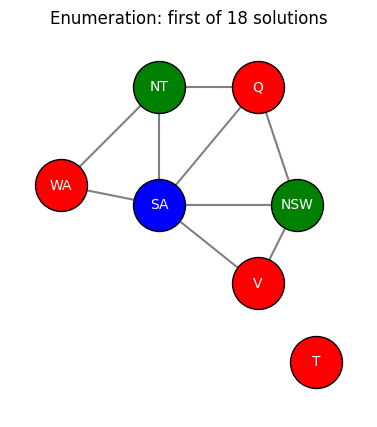

In [ ]:
map_all, checked = enumerate_csp(map_csp)
print("Checked:",checked,"solutions:",len(map_all))
assert checked==2187 and len(map_all)==18
draw_map(map_all[0],"Enumeration: first of 18 solutions")


* All 18 assignments are certified by direct constraint checks. Named color permutations and Tasmania choices are counted separately.


## 1.2 Backtracking
* Assign WA, NT, SA, Q, NSW, V, T in that order.
* To expose an actual undo operation, also run a deliberately difficult decision order.

### Algorithm
```text
Assign a legal color; recurse; undo when later decisions fail.
```


Backtracking solution: {'WA': 'Red', 'NT': 'Green', 'SA': 'Blue', 'Q': 'Red', 'NSW': 'Green', 'V': 'Red', 'T': 'Red'}
Statistics: {'calls': 8, 'attempts': 7, 'backtracks': 0, 'pruned': 0} milliseconds: 0.045


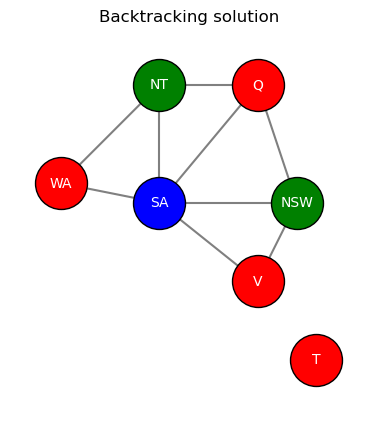

('assign', 'WA', 'Red')
('assign', 'Q', 'Green')
('assign', 'NT', 'Blue')
('undo', 'NT', 'Blue')
('undo', 'Q', 'Green')
('assign', 'Q', 'Red')
('assign', 'NT', 'Green')
('assign', 'SA', 'Blue')
('assign', 'NSW', 'Green')
('assign', 'V', 'Red')
('assign', 'T', 'Red')


In [ ]:
a,s,_ = run_method(map_csp,"Backtracking")
map_results["Backtracking"] = s
draw_map(a,"Backtracking solution")
order = ["WA","Q","NT","SA","NSW","V","T"]
domains = {x:colors[:] for x in order};domains["Q"]=["Green","Red","Blue"]
hard_order = BinaryCSP(domains,map_edges,not_equal)
a,s,events = solve(hard_order,trace=True)
for event in events[:16]: print(event)
assert hard_order.valid(a) and any(e[0]=="undo" for e in events)


* WA=Red and Q=Green force NT=Blue; SA then has no color.
* Search undoes NT and Q, tries Q=Red, and finds a solution.
* Changing order does not change the allowed assignments.


## 1.3 MRV
* MRV counts currently legal values.
* After WA=Red and NT=Green, SA has only Blue.

### Algorithm
```text
Select an unassigned variable with minimum legal-domain size.
```


In [ ]:
a,s,_=run_method(map_csp,"MRV",mrv=True)
map_results["MRV"]=s

MRV solution: {'WA': 'Red', 'NT': 'Green', 'SA': 'Blue', 'Q': 'Red', 'NSW': 'Green', 'V': 'Red', 'T': 'Red'}
Statistics: {'calls': 8, 'attempts': 7, 'backtracks': 0, 'pruned': 0} milliseconds: 0.072


* Initial domains tie, so MRV initially uses insertion order. Its decisions become more informative after assignments constrain domains.


## 1.4 Degree tie breaking
* Initially every domain has three values.
* Degrees: SA=5; NT=Q=NSW=3; WA=V=2; T=0.

### Algorithm
```text
Among MRV ties, select maximum unassigned-neighbor count.
```


In [ ]:
print({x:len(map_csp.neighbors[x]) for x in map_csp.variables})
a,s,events=run_method(map_csp,"MRV + degree",mrv=True,degree=True,trace=True)
map_results["MRV + degree"]=s
print("First assignment:",events[0])
assert events[0][1]=="SA"


{'WA': 2, 'NT': 3, 'SA': 5, 'Q': 3, 'NSW': 3, 'V': 2, 'T': 0}
MRV + degree solution: {'SA': 'Red', 'NT': 'Green', 'Q': 'Blue', 'NSW': 'Green', 'WA': 'Blue', 'V': 'Blue', 'T': 'Red'}
Statistics: {'calls': 8, 'attempts': 7, 'backtracks': 0, 'pruned': 0} milliseconds: 0.081
First assignment: ('assign', 'SA', 'Red')


* Degree chooses SA first because it touches the most unresolved restrictions. This can differ from fixed-order backtracking.


## 1.5 LCV
* Consider Q after WA=Red, NT=Green.
* SA={Blue}, NSW={Red,Green,Blue}.
* Q=Red removes one neighbor value; Q=Blue removes two.
* This is a value-order illustration; MRV would select singleton SA before Q.

### Algorithm
```text
Count incompatible legal neighbor values; try the lowest score first.
```


In [ ]:
a,s,_=run_method(map_csp,"MRV + degree + LCV",mrv=True,degree=True,lcv=True)
map_results["MRV + degree + LCV"]=s
print("Worked Q scores: Red=1; Blue=2")


MRV + degree + LCV solution: {'SA': 'Red', 'NT': 'Green', 'Q': 'Blue', 'NSW': 'Green', 'WA': 'Blue', 'V': 'Blue', 'T': 'Red'}
Statistics: {'calls': 8, 'attempts': 7, 'backtracks': 0, 'pruned': 0} milliseconds: 0.117
Worked Q scores: Red=1; Blue=2


* LCV prefers Red for Q in the stated partial state.
* It preserves local choices; it does not count complete future solutions.


## 1.6 Forward checking
* WA=Red removes Red from NT and SA.
* Q=Green then leaves NT=SA=Blue. No domain is empty, but their mutual edge is already impossible.

### Algorithm
```text
Filter unassigned neighbors after each decision; reject domain wipeout.
```


In [ ]:
d=copy_domains(map_csp);partial={"WA":"Red","Q":"Green"}
for x,a in partial.items():d[x]=[a]
assert forward_check(map_csp,"WA","Red",partial,d)
assert forward_check(map_csp,"Q","Green",partial,d)
print("Forward-checked domains:",d)
assert d["NT"]==d["SA"]==["Blue"]
map_fc_domains={x:v[:] for x,v in d.items()}
a,s,_=run_method(map_csp,"Forward checking",inference="fc",mrv=True,degree=True,lcv=True)
map_results["Forward checking"]=s


Forward-checked domains: {'WA': ['Red'], 'NT': ['Blue'], 'SA': ['Blue'], 'Q': ['Green'], 'NSW': ['Red', 'Blue'], 'V': ['Red', 'Green', 'Blue'], 'T': ['Red', 'Green', 'Blue']}
Forward checking solution: {'SA': 'Red', 'NT': 'Green', 'Q': 'Blue', 'NSW': 'Green', 'WA': 'Blue', 'V': 'Blue', 'T': 'Red'}
Statistics: {'calls': 8, 'attempts': 7, 'backtracks': 0, 'pruned': 9} milliseconds: 0.103


* This cell performs real forward checking, rather than repeating the baseline. The partial branch demonstrates its blind spot between unassigned neighbors.


## 1.7 AC-3
* AC-3 on the unconstrained map leaves all three colors available.
* On the previous partial branch, NT and SA have no unequal pair of supporting values.

### Algorithm
```text
Revise directed arcs until a fixed point or an empty domain.
```


In [ ]:
initial=copy_domains(map_csp)
assert ac3(map_csp,initial)
print("Unassigned map after AC-3:",initial)
propagated={x:v[:] for x,v in map_fc_domains.items()}
ok=ac3(map_csp,propagated)
print("Partial branch accepted:",ok,"domains:",propagated)
assert not ok and any(not v for v in propagated.values())


Unassigned map after AC-3: {'WA': ['Red', 'Green', 'Blue'], 'NT': ['Red', 'Green', 'Blue'], 'SA': ['Red', 'Green', 'Blue'], 'Q': ['Red', 'Green', 'Blue'], 'NSW': ['Red', 'Green', 'Blue'], 'V': ['Red', 'Green', 'Blue'], 'T': ['Red', 'Green', 'Blue']}
Partial branch accepted: False domains: {'WA': ['Red'], 'NT': [], 'SA': ['Blue'], 'Q': ['Green'], 'NSW': ['Red', 'Blue'], 'V': ['Red', 'Green', 'Blue'], 'T': ['Red', 'Green', 'Blue']}


* False proves WA=Red, Q=Green cannot extend to a solution.
* It does not prove that the original three-color map is unsatisfiable.


## 1.8 Maintaining arc consistency
* MAC interleaves backtracking with AC-3.
* Each chosen color becomes a singleton domain before propagation.

### Algorithm
```text
Run initial AC-3; decide; propagate incoming arcs; recurse or undo.
```


MAC solution: {'SA': 'Red', 'NT': 'Green', 'NSW': 'Green', 'WA': 'Blue', 'Q': 'Blue', 'V': 'Blue', 'T': 'Red'}
Statistics: {'calls': 8, 'attempts': 7, 'backtracks': 0, 'pruned': 9} milliseconds: 0.176


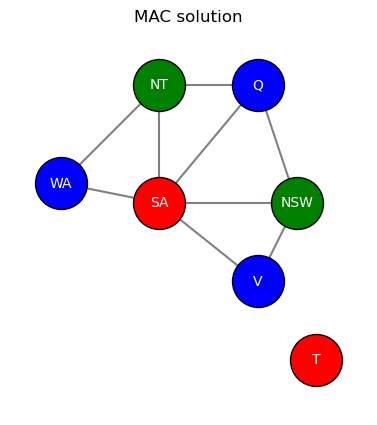

In [ ]:
a,s,_=run_method(map_csp,"MAC",inference="mac",mrv=True,degree=True,lcv=True)
map_results["MAC"]=s
draw_map(a,"MAC solution")


* MAC returns a complete verified assignment.
* Nonempty AC-3 domains alone would not be a complete solution certificate.


## 1.9 Min-conflicts
* Start with a complete random map coloring.
* Move one conflicted state to a color with the fewest incident violations.

### Algorithm
```text
Repair minimum-conflict values; break ties randomly; restart if needed.
```


Found: {'WA': 'Blue', 'NT': 'Green', 'SA': 'Red', 'Q': 'Blue', 'NSW': 'Green', 'V': 'Blue', 'T': 'Red'} recorded states: 9


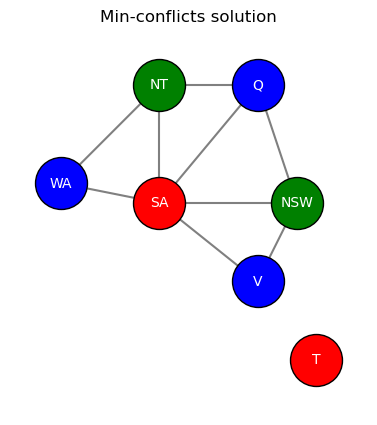

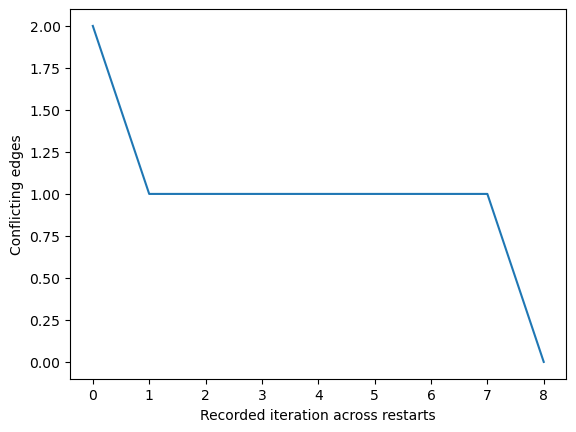

In [ ]:
map_local,h=min_conflicts(map_csp,seed=42)
print("Found:",map_local,"recorded states:",len(h))
if map_local is not None:
    assert map_csp.valid(map_local);draw_map(map_local,"Min-conflicts solution")
else:print("Budget exhausted; infeasibility is not established.")
plt.plot(h);plt.xlabel("Recorded iteration across restarts");plt.ylabel("Conflicting edges");plt.show()


* A zero final conflict count certifies a solution. A nonzero count at budget exhaustion only reports an unsuccessful search.


## 1.10 Tree solving after conditioning
* Fix SA and Q. Removing them leaves WA—NT and NSW—V, plus isolated T.
* Every remaining component is a tree, so the shared tree solver applies.

### Algorithm
```text
Enumerate SA and Q; filter residual components; solve each tree.
```


Cutset trials: 2 solution: {'SA': 'Red', 'Q': 'Green', 'WA': 'Green', 'NT': 'Blue', 'NSW': 'Blue', 'V': 'Green', 'T': 'Red'}


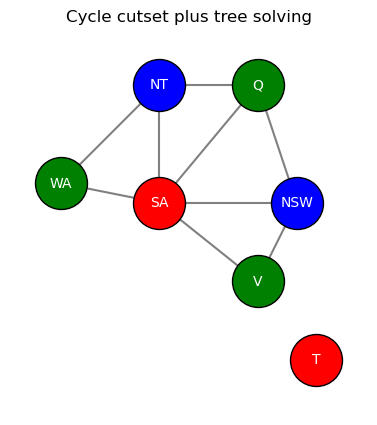

In [ ]:
a,trials=cutset_solve(map_csp,["SA","Q"])
print("Cutset trials:",trials,"solution:",a)
assert map_csp.valid(a)
draw_map(a,"Cycle cutset plus tree solving")


* No edge is ignored. Constraints incident to the cutset become domain restrictions on residual variables. This is a correct reduction, not direct tree solving on the cyclic map.


## 2 N-Queens
* Main comparison: N=4, so exhaustive enumeration checks only 4⁴ = 256 assignments.
* Q[c] is the row of the queen in column c. Exactly one queen per column is implicit.
* For distinct columns c and d: Q[c] ≠ Q[d] and |Q[c]−Q[d]| ≠ |c−d|.
* c and d are column indices. Row distance is |Q[c]−Q[d]|; column distance is |c−d|. Equal distances imply a shared diagonal.
* Q=[1,3,0,2] is valid. For columns 0 and 1, row distance |1−3|=2 differs from column distance |0−1|=1.
* N=8 and N=30 are additional sizes of the same example, not additional main examples.

### Algorithm
```text
Create one row-valued variable per column; constrain every queen pair.
```


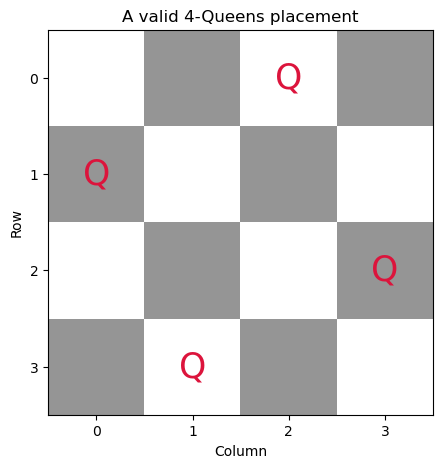

In [ ]:
def queens_csp(n):
    return BinaryCSP({c:list(range(n)) for c in range(n)},list(combinations(range(n),2)),
        lambda c,r,d,s:r!=s and abs(r-s)!=abs(c-d))
queens=queens_csp(4);queen_results={}
def draw_queens(answer,title="N-Queens"):
    n=len(answer);fig,ax=plt.subplots(figsize=(5,5))
    ax.imshow(np.indices((n,n)).sum(axis=0)%2,cmap="Greys",vmin=0,vmax=2)
    for c,r in answer.items():ax.text(c,r,"Q",ha="center",va="center",color="crimson",fontsize=max(10,100//n))
    ax.set_xticks(range(n));ax.set_yticks(range(n));ax.set_xlabel("Column");ax.set_ylabel("Row")
    ax.set_title(title);plt.show()
draw_queens(dict(enumerate([1,3,0,2])),"A valid 4-Queens placement")


* The graph is complete: every pair of queens can attack.
* All comparisons below use the identical 4-Queens model unless a larger N is explicitly stated.


## 2.1 Exhaustive enumeration
* Generate every row list, including placements with shared rows.

### Algorithm
```text
Generate 256 complete assignments; test row and diagonal safety.
```


Checked: 256 solutions: 2 [{0: 1, 1: 3, 2: 0, 3: 2}, {0: 2, 1: 0, 2: 3, 3: 1}]


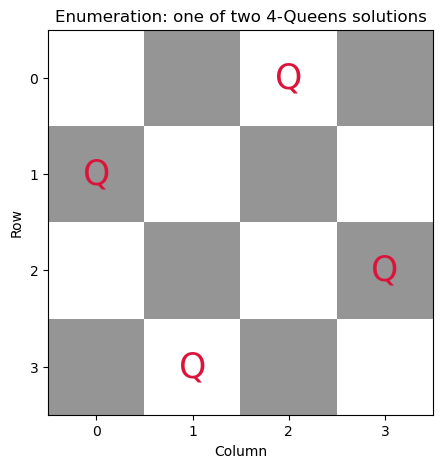

In [ ]:
queen_all,checked=enumerate_csp(queens)
print("Checked:",checked,"solutions:",len(queen_all),queen_all)
assert checked==256 and len(queen_all)==2
draw_queens(queen_all[0],"Enumeration: one of two 4-Queens solutions")


* There are two solutions when reflected boards are counted separately. Enumeration is complete on this small domain.


## 2.2 Backtracking
* Place one queen per column in column order. Test rows against earlier queens.

### Algorithm
```text
Try a safe row; recurse to the next column; undo on a dead end.
```


Backtracking solution: {0: 1, 1: 3, 2: 0, 3: 2}
Statistics: {'calls': 9, 'attempts': 8, 'backtracks': 4, 'pruned': 0} milliseconds: 0.041
First undo operations: [('undo', 1, 2), ('undo', 2, 1), ('undo', 1, 3), ('undo', 0, 0)]


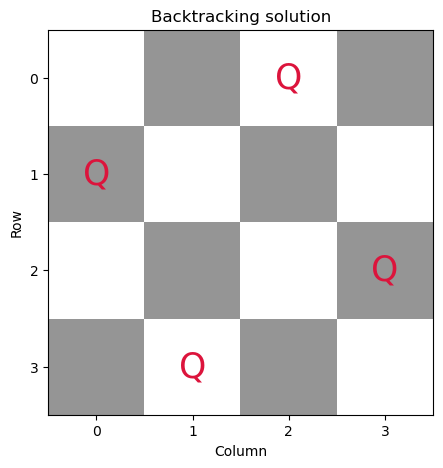

In [ ]:
a,s,events=run_method(queens,'Backtracking',trace=True,**{})
queen_results['Backtracking']=s
assert queens.valid(a)
print("First undo operations:",[e for e in events if e[0]=="undo"][:5])
draw_queens(a,"Backtracking solution")


* Early choices can block a later column. Undo operations demonstrate genuine backtracking.


## 2.3 MRV
* Choose the column with the fewest currently safe rows.

### Algorithm
```text
Recalculate legal rows; select the smallest set.
```


In [ ]:
a,s,events=run_method(queens,'MRV',trace=True,**{'mrv': True})
queen_results['MRV']=s
assert queens.valid(a)


MRV solution: {0: 1, 1: 3, 2: 0, 3: 2}
Statistics: {'calls': 9, 'attempts': 8, 'backtracks': 4, 'pruned': 0} milliseconds: 0.153


* MRV detects tightly constrained columns before loosely constrained ones.


## 2.4 MRV + degree
* Every unassigned column is adjacent to all other unassigned columns.

### Algorithm
```text
Break MRV ties by remaining degree.
```


In [ ]:
a,s,events=run_method(queens,'MRV + degree',trace=True,**{'mrv': True, 'degree': True})
queen_results['MRV + degree']=s
assert queens.valid(a)


MRV + degree solution: {0: 1, 1: 3, 2: 0, 3: 2}
Statistics: {'calls': 9, 'attempts': 8, 'backtracks': 4, 'pruned': 0} milliseconds: 0.243


### Explanation of the result
* Degrees tie in this complete graph, so degree cannot distinguish tied columns. It is implemented but offers no extra discrimination here.


## 2.5 MRV + degree + LCV
* Score each candidate row by the number of legal rows it removes from other columns.

### Algorithm
```text
Try the row with the smallest total neighbor-value loss.
```


In [ ]:
a,s,events=run_method(queens,'MRV + degree + LCV',trace=True,**{'mrv': True, 'degree': True, 'lcv': True})
queen_results['MRV + degree + LCV']=s
assert queens.valid(a)


MRV + degree + LCV solution: {0: 1, 1: 3, 2: 0, 3: 2}
Statistics: {'calls': 9, 'attempts': 8, 'backtracks': 4, 'pruned': 0} milliseconds: 0.248


* The score counts both shared-row and diagonal restrictions. Lower scores preserve local flexibility.


## 2.6 Forward checking
* After placing a queen, remove its row and attacking diagonal positions from every unassigned column.

### Algorithm
```text
Filter unassigned columns; reject any empty row domain.
```


In [ ]:
a,s,events=run_method(queens,'Forward checking',trace=True,**{'inference': 'fc', 'mrv': True, 'degree': True, 'lcv': True})
queen_results['Forward checking']=s
assert queens.valid(a)
d=copy_domains(queens);d[0]=[0]
assert forward_check(queens,0,0,{0:0},d)
print("After Q[0]=0:",d)


Forward checking solution: {0: 1, 1: 3, 2: 0, 3: 2}
Statistics: {'calls': 7, 'attempts': 8, 'backtracks': 2, 'pruned': 20} milliseconds: 0.116
After Q[0]=0: {0: [0], 1: [2, 3], 2: [1, 3], 3: [1, 2]}


* For Q[0]=0 on N=4, Q[1] keeps rows {2,3}, Q[2] keeps {1,3}, and Q[3] keeps {1,2}.


## 2.7 AC-3
* Initial 4-Queens domains remain arc consistent without a placement.
* Setting Q[0]=0 leads to a contradiction under propagation.

### Algorithm
```text
Restrict the chosen column, then repeatedly revise queen-pair arcs.
```


In [ ]:
d=copy_domains(queens);print("Initial AC-3:",ac3(queens,d),d)
d=copy_domains(queens);d[0]=[0]
ok=ac3(queens,d);print("Q[0]=0 accepted:",ok,d)
assert not ok
# A different branch is feasible.
d=copy_domains(queens);d[0]=[1]
assert ac3(queens,d)
print("Q[0]=1 propagated domains:",d)


Initial AC-3: True {0: [0, 1, 2, 3], 1: [0, 1, 2, 3], 2: [0, 1, 2, 3], 3: [0, 1, 2, 3]}
Q[0]=0 accepted: False {0: [0], 1: [2, 3], 2: [1], 3: []}
Q[0]=1 propagated domains: {0: [1], 1: [3], 2: [0], 3: [2]}


* Root arc consistency does not establish a complete solution. Propagation can reject a bad placement before deeper search.


## 2.8 MAC
* Propagate row and diagonal support losses after each placement.

### Algorithm
```text
Decide a row; run AC-3 on affected arcs; recurse or undo.
```


MAC solution: {0: 1, 1: 3, 2: 0, 3: 2}
Statistics: {'calls': 5, 'attempts': 5, 'backtracks': 0, 'pruned': 19} milliseconds: 0.133


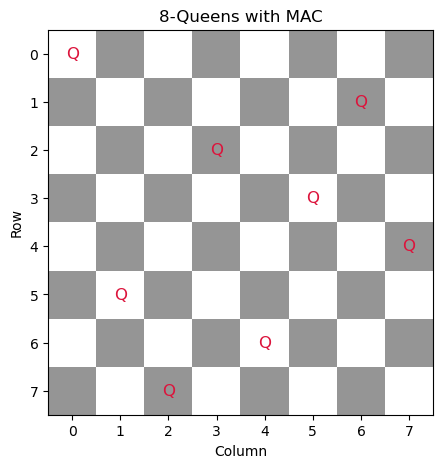

In [ ]:
a,s,events=run_method(queens,'MAC',trace=True,**{'inference': 'mac', 'mrv': True, 'degree': True, 'lcv': True})
queen_results['MAC']=s
assert queens.valid(a)
q8,s8,_=solve(queens_csp(8),inference="mac",mrv=True,degree=True,lcv=True)
assert queens_csp(8).valid(q8)
draw_queens(q8,"8-Queens with MAC")


* MAC detects more consequences than one-step filtering, but can add overhead on easy instances.


## 2.9 Min-conflicts
* Begin with a complete row assignment. Score a move by attacking pairs incident to the selected queen.
* For Q=[0,0,0,0], moving column 1 to rows 0,1,2,3 gives local scores 3,2,1,0. Moving to row 3 reduces total attacking pairs from 6 to 3.

### Algorithm
```text
Choose a conflicted column; minimize attacks; randomly break ties; restart.
```


N: 4 solved: True states: 14


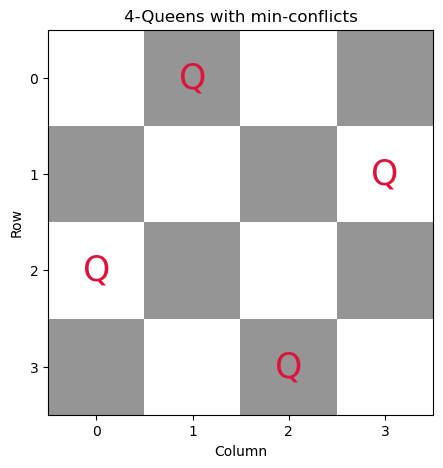

N: 30 solved: True states: 58


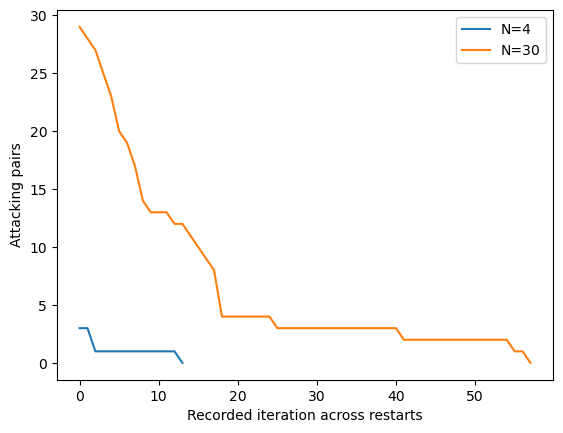

In [ ]:
for n in [4,30]:
    model=queens_csp(n)
    a,h=min_conflicts(model,seed=42,max_steps=3000,restarts=20)
    print("N:",n,"solved:",a is not None,"states:",len(h))
    if a is not None:assert model.valid(a)
    if n==4 and a is not None:draw_queens(a,"4-Queens with min-conflicts")
    plt.plot(h,label=f"N={n}")
plt.xlabel("Recorded iteration across restarts");plt.ylabel("Attacking pairs");plt.legend();plt.show()


* A successful repair trajectory reaches zero attacking pairs. The direct implementation is quadratic per repair step; it is not an optimized million-queens solver.


## 2.10 Tree solving after conditioning
* The queen graph K₄ is cyclic. Fix two columns to leave one edge, which is a tree.
* More generally Kₙ needs at least n−2 vertices removed to leave a forest.

### Algorithm
```text
Enumerate columns 0 and 1; filter and tree-solve columns 2 and 3.
```


Cutset trials: 8 solution: {0: 1, 1: 3, 2: 0, 3: 2}


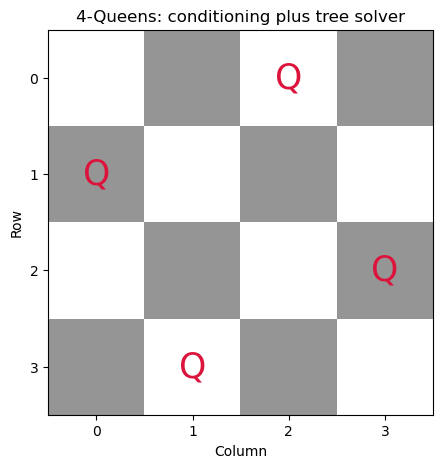

In [ ]:
a,trials=cutset_solve(queens,[0,1])
print("Cutset trials:",trials,"solution:",a)
assert queens.valid(a);draw_queens(a,"4-Queens: conditioning plus tree solver")


* This is exact but its large cutset makes the method unattractive as N grows. Structural methods help most when a small cutset exists.


## 3 Cryptarithmetic
* Main puzzle: I + BB = ILL in base 10.
* BB means 11B; ILL means 100I+11L.
* Distinct letters have distinct digits. I and B are nonzero leading digits; L may be zero.
* Equation: I + 11B = 100I + 11L, so B = 9I + L.
* Since 1 ≤ I ≤ 9, 1 ≤ B ≤ 9, and L ≥ 0, I must be 1. Then B=9 and L=0.
* Numeric check: 1 + 99 = 100.
* The small puzzle makes all methods transparent. The larger SEND + MORE = MONEY application follows within this section.

## Binary encoding of the arithmetic relation
* Introduce an auxiliary variable H whose values are tuples (I,B,L) satisfying the addition equation and leading-digit restrictions.
* Link each letter to its coordinate in H. Keep pairwise letter inequalities as explicit edges.
* H is an encoding variable, not an additional letter.
* Enumerating allowed tuples performs local relation construction. The time to construct this table is separate from the later solver time. The table happens to contain one tuple in this small puzzle.
* AC-3 applies to the binary encoding. It is not being applied directly to an arbitrary eight-variable arithmetic predicate.

### Algorithm
```text
Construct allowed arithmetic tuples.
For each letter, enforce equality to its coordinate in the tuple variable.
Enforce different digits between distinct letters.
```


In [ ]:
letters=["I","B","L"]
letter_domains={"I":list(range(1,10)),"B":list(range(1,10)),"L":list(range(10))}
allowed=[(i,b,l) for i,b,l in product(*letter_domains.values())
         if i+11*b==100*i+11*l]
crypt_domains={**letter_domains,"H":allowed}
crypt_edges=list(combinations(letters,2))+[(x,"H") for x in letters]
def crypt_compatible(x,a,y,b):
    if x=="H":return a[letters.index(y)]==b
    if y=="H":return a==b[letters.index(x)]
    return a!=b
crypt=BinaryCSP(crypt_domains,crypt_edges,crypt_compatible)
crypt_results={}
def valid_letters(a):
    return (set(a)==set(letters) and all(a[x] in letter_domains[x] for x in letters)
            and len(set(a.values()))==3 and a["I"]+11*a["B"]==100*a["I"]+11*a["L"])
def show_crypt(a,title="Cryptarithmetic solution"):
    visible={x:a[x] for x in letters}
    assert valid_letters(visible)
    print("Letter assignment:",visible)
    print(f"{visible['I']} + {11*visible['B']} = {100*visible['I']+11*visible['L']}")
    fig,ax=plt.subplots(figsize=(6,3));ax.axis("off");ax.set_title(title)
    ax.text(.5,.70,"  I + BB = ILL",ha="center",fontsize=22,family="monospace")
    ax.text(.5,.40,f"  {visible['I']} + {11*visible['B']} = {100*visible['I']+11*visible['L']}",ha="center",fontsize=22,family="monospace",color="royalblue")
    plt.show()
print("Allowed arithmetic tuples:",allowed)


Allowed arithmetic tuples: [(1, 9, 0)]


* A complete binary-model solution includes H, but the displayed answer shows only the original letters.
* The original-letter validator independently checks arithmetic and distinctness, without relying on H.
* A larger allowed-tuple table can become expensive; carry decompositions avoid one huge relation in larger puzzles.


## 3.1 Exhaustive enumeration
* Enumerate original letters only: 9 × 9 × 10 = 810 candidates.
* Reject repeated digits and arithmetic violations before extending a solution with H.

### Algorithm
```text
Generate I B L assignments; check original arithmetic and digit restrictions.
```


Checked: 810 solutions: [{'I': 1, 'B': 9, 'L': 0, 'H': (1, 9, 0)}]
Letter assignment: {'I': 1, 'B': 9, 'L': 0}
1 + 99 = 100


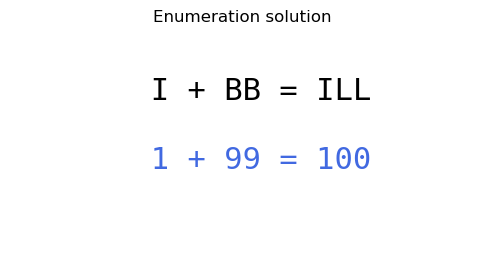

In [ ]:
crypt_all=[];checked=0
for values in product(*letter_domains.values()):
    checked+=1;a=dict(zip(letters,values))
    if valid_letters(a):crypt_all.append({**a,"H":tuple(values)})
print("Checked:",checked,"solutions:",crypt_all)
assert checked==810 and len(crypt_all)==1 and crypt.valid(crypt_all[0])
show_crypt(crypt_all[0],"Enumeration solution")


* Exactly one original-letter assignment is valid. The auxiliary tuple extends it uniquely, so the encoding introduces no extra original solutions.


## 3.2 Backtracking
* Assign I, B, L, then H. The tuple links reject arithmetic-incompatible combinations.

### Algorithm
```text
Assign legal digits and auxiliary values; undo failures.
```


In [ ]:
a,s,_=run_method(crypt,'Backtracking',**{})
crypt_results['Backtracking']=s
assert valid_letters({x:a[x] for x in letters})


Backtracking solution: {'I': 1, 'B': 9, 'L': 0, 'H': (1, 9, 0)}
Statistics: {'calls': 68, 'attempts': 67, 'backtracks': 63, 'pruned': 0} milliseconds: 0.158


* Even though the relation table was constructed earlier, baseline search does not propagate its restrictions into letter domains.


## 3.3 MRV
* H has one allowed tuple, so its domain is smaller than the letter domains.

### Algorithm
```text
Select the smallest legal domain before branching.
```


In [ ]:
a,s,_=run_method(crypt,'MRV',**{'mrv': True})
crypt_results['MRV']=s
assert valid_letters({x:a[x] for x in letters})


MRV solution: {'H': (1, 9, 0), 'I': 1, 'B': 9, 'L': 0}
Statistics: {'calls': 5, 'attempts': 4, 'backtracks': 0, 'pruned': 0} milliseconds: 0.073


* Selecting H first immediately makes coordinate checks informative for subsequent letter choices.


## 3.4 MRV + degree
* MRV chooses the singleton H. The degree rule resolves any later MRV ties.

### Algorithm
```text
Use remaining degree among equal legal-domain sizes.
```


In [ ]:
a,s,_=run_method(crypt,'MRV + degree',**{'mrv': True, 'degree': True})
crypt_results['MRV + degree']=s
assert valid_letters({x:a[x] for x in letters})


MRV + degree solution: {'H': (1, 9, 0), 'I': 1, 'B': 9, 'L': 0}
Statistics: {'calls': 5, 'attempts': 4, 'backtracks': 0, 'pruned': 0} milliseconds: 0.081


* In this symmetric four-variable complete graph, tied unassigned variables also have equal degree; the degree heuristic adds no distinction.


## 3.5 MRV + degree + LCV
* Score each candidate digit or tuple by losses across linked domains.

### Algorithm
```text
Try values with the fewest incompatible neighbor values.
```


In [ ]:
a,s,_=run_method(crypt,'MRV + degree + LCV',**{'mrv': True, 'degree': True, 'lcv': True})
crypt_results['MRV + degree + LCV']=s
assert valid_letters({x:a[x] for x in letters})


MRV + degree + LCV solution: {'H': (1, 9, 0), 'I': 1, 'B': 9, 'L': 0}
Statistics: {'calls': 5, 'attempts': 4, 'backtracks': 0, 'pruned': 0} milliseconds: 0.102


* The arithmetic table is already singleton, so there is limited room for LCV to improve this example.


## 3.6 Forward checking
* Assign H=(1,9,0), then remove every letter value inconsistent with its coordinate.

### Algorithm
```text
Filter neighboring letter domains after the H decision.
```


In [ ]:
a,s,_=run_method(crypt,'Forward checking',**{'inference': 'fc', 'mrv': True, 'degree': True, 'lcv': True})
crypt_results['Forward checking']=s
assert valid_letters({x:a[x] for x in letters})
d=copy_domains(crypt);d["H"]=[allowed[0]]
assert forward_check(crypt,"H",allowed[0],{"H":allowed[0]},d)
print("Letter domains after H assignment:",{x:d[x] for x in letters})


Forward checking solution: {'H': (1, 9, 0), 'I': 1, 'B': 9, 'L': 0}
Statistics: {'calls': 5, 'attempts': 4, 'backtracks': 0, 'pruned': 25} milliseconds: 0.066
Letter domains after H assignment: {'I': [1], 'B': [9], 'L': [0]}


* This reduces I to 1, B to 9, and L to 0 in one forward-checking step.


## 3.7 AC-3
* Every letter value must be supported by H.
* The sole tuple supports I=1, B=9, L=0.

### Algorithm
```text
Revise letter-to-H arcs and propagate until a fixed point.
```


After AC-3: {'I': [1], 'B': [9], 'L': [0], 'H': [(1, 9, 0)]}
Letter assignment: {'I': 1, 'B': 9, 'L': 0}
1 + 99 = 100


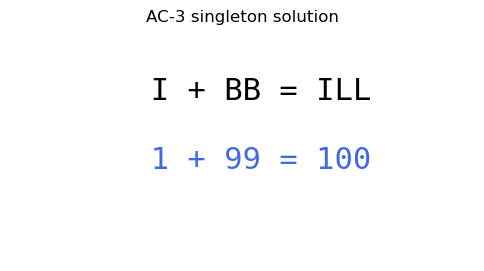

In [ ]:
d=copy_domains(crypt)
assert ac3(crypt,d)
print("After AC-3:",d)
assert all(len(v)==1 for v in d.values())
a={x:v[0] for x,v in d.items()}
assert crypt.valid(a);show_crypt(a,"AC-3 singleton solution")


* In this particular instance, singleton arc-consistent domains form a verified solution. In general, multiple remaining values do not guarantee feasibility.


## 3.8 MAC
* Initial AC-3 makes the encoded puzzle singleton before decisions.

### Algorithm
```text
Initial AC-3; branch over any remaining alternatives; maintain supports.
```


MAC solution: {'I': 1, 'B': 9, 'L': 0, 'H': (1, 9, 0)}
Statistics: {'calls': 5, 'attempts': 4, 'backtracks': 0, 'pruned': 25} milliseconds: 0.099
Letter assignment: {'I': 1, 'B': 9, 'L': 0}
1 + 99 = 100


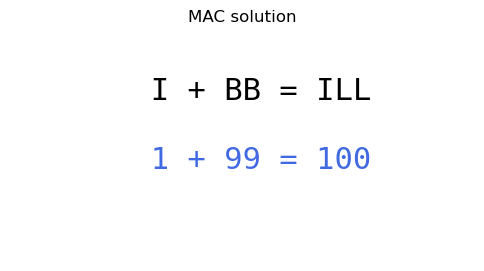

In [ ]:
a,s,_=run_method(crypt,'MAC',**{'inference': 'mac', 'mrv': True, 'degree': True, 'lcv': True})
crypt_results['MAC']=s
assert valid_letters({x:a[x] for x in letters})
show_crypt(a,"MAC solution")


* The easy singleton structure means MAC has little search left. This does not imply all cryptarithmetic is easy.


## 3.9 Min-conflicts
* Start with random values for all letters and H.
* Repair violated coordinate and distinct-digit edges.
* A tuple-valued auxiliary variable is handled like any other finite-domain variable.

### Algorithm
```text
Choose a conflicted variable; minimize violated binary relations; restart if necessary.
```


Solution: {'I': 1, 'B': 9, 'L': 0, 'H': (1, 9, 0)} recorded states: 7
Letter assignment: {'I': 1, 'B': 9, 'L': 0}
1 + 99 = 100


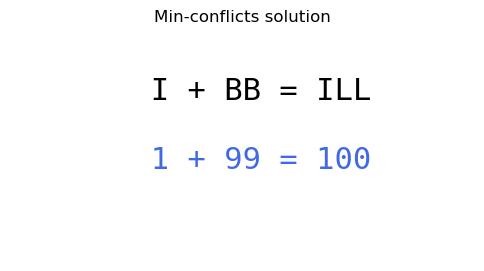

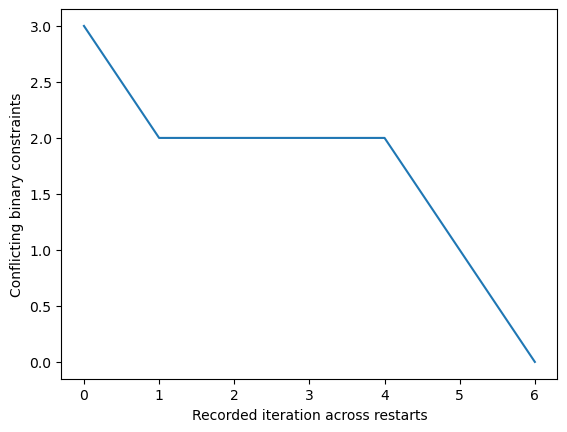

In [ ]:
a,h=min_conflicts(crypt,seed=42,max_steps=3000,restarts=30)
print("Solution:",a,"recorded states:",len(h))
if a is not None:assert crypt.valid(a);show_crypt(a,"Min-conflicts solution")
else:print("Budget exhausted; no infeasibility claim.")
plt.plot(h);plt.xlabel("Recorded iteration across restarts");plt.ylabel("Conflicting binary constraints");plt.show()


* Conflict scores refer to this binary encoding, not directly to numerical addition error. Different encodings can create different local-search landscapes.


## 3.10 Tree solving after conditioning
* The explicit digit-inequality edges make the graph K₄, including H. Fix I and B; residual L—H is a tree.
* Keep every original restriction by domain filtering.

### Algorithm
```text
Enumerate I and B; filter L and H; solve the remaining tree.
```


Cutset trials: 9 solution: {'I': 1, 'B': 9, 'L': 0, 'H': (1, 9, 0)}
Letter assignment: {'I': 1, 'B': 9, 'L': 0}
1 + 99 = 100


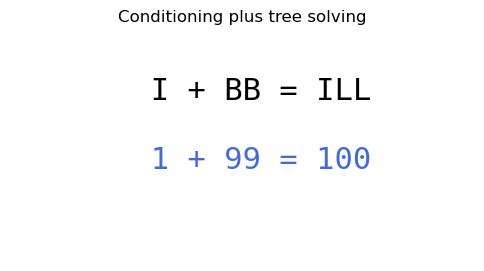

In [ ]:
a,trials=cutset_solve(crypt,["I","B"])
print("Cutset trials:",trials,"solution:",a)
assert crypt.valid(a);show_crypt(a,"Conditioning plus tree solving")


* The result satisfies the original addition and distinct-digit rules. The method is valid because the residual graph is explicitly checked to be a forest.


## 3.11 Larger cryptarithmetic application SEND MORE MONEY
* Distinct letters S E N D M O R Y denote digits; S and M are nonzero.
* A carry-based enumerator performs column checks before constructing full sums. This is specialized structured enumeration, not the generic AC-3 solver.
* Units: D+E=Y+10c1; tens: N+R+c1=E+10c2; hundreds: E+O+c2=N+10c3; thousands: S+M+c3=O+10c4; c4=M.
* Since the sum has five digits, M=1.

### Algorithm
```text
Choose distinct digits; derive column results and carries; reject each inconsistent column immediately.
```


In [ ]:
def send_more_money():
    answers=[];m=1
    for s in range(2,10):
        for e in range(10):
            if e in {s,m}:continue
            for d in range(10):
                if d in {s,m,e}:continue
                c1,y=divmod(d+e,10)
                if y in {s,m,e,d}:continue
                for n in range(10):
                    if n in {s,m,e,d,y}:continue
                    for r in range(10):
                        if r in {s,m,e,d,y,n}:continue
                        c2,tens=divmod(n+r+c1,10)
                        if tens!=e:continue
                        for o in range(10):
                            if o in {s,m,e,d,y,n,r}:continue
                            c3,hundreds=divmod(e+o+c2,10)
                            if hundreds!=n:continue
                            c4,thousands=divmod(s+m+c3,10)
                            if thousands==o and c4==m:
                                answers.append(dict(zip("SENDMORY",[s,e,n,d,m,o,r,y])))
    return answers
large_answers=send_more_money()
assert len(large_answers)==1
for a in large_answers:
    word=lambda w:int("".join(str(a[x]) for x in w))
    assert len(set(a.values()))==8 and a["S"]!=0 and a["M"]!=0
    assert word("SEND")+word("MORE")==word("MONEY")
    print(a);print(word("SEND"),"+",word("MORE"),"=",word("MONEY"))


{'S': 9, 'E': 5, 'N': 6, 'D': 7, 'M': 1, 'O': 0, 'R': 8, 'Y': 2}
9567 + 1085 = 10652


* The unique result is 9567 + 1085 = 10652. Carries are c1=1, c2=1, c3=0, c4=1. The column decomposition makes arithmetic rejection possible earlier than a full eight-letter predicate.


## 4 Comparison and verification
* The three examples each have runnable demonstrations of all ten techniques, including tree solving through conditioning.
* MRV, degree, and LCV are shown separately so their contributions are visible.
* Root AC-3 need not solve a problem; budgeted min-conflicts is incomplete.
* The binary representation changes both propagation and local-search behavior. Cross-example runtime comparisons are not claims about problem-family difficulty.

### Algorithm
```text
Collect statistics for the six complete-search configurations.
Compare attempts and pruned values within the same model.
Run independent enumeration-based correctness checks.
```



 Australia
Backtracking              {'calls': 8, 'attempts': 7, 'backtracks': 0, 'pruned': 0}
MRV                       {'calls': 8, 'attempts': 7, 'backtracks': 0, 'pruned': 0}
MRV + degree              {'calls': 8, 'attempts': 7, 'backtracks': 0, 'pruned': 0}
MRV + degree + LCV        {'calls': 8, 'attempts': 7, 'backtracks': 0, 'pruned': 0}
Forward checking          {'calls': 8, 'attempts': 7, 'backtracks': 0, 'pruned': 9}
MAC                       {'calls': 8, 'attempts': 7, 'backtracks': 0, 'pruned': 9}


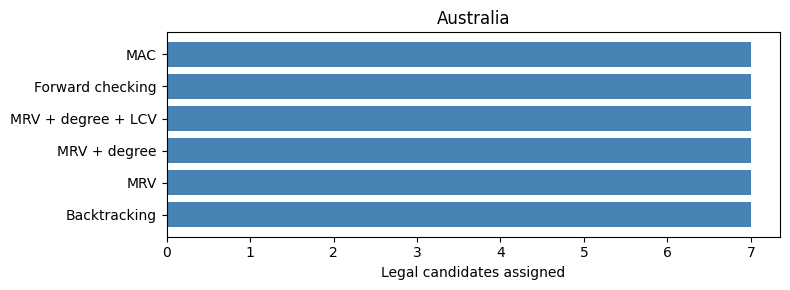


 4-Queens
Backtracking              {'calls': 9, 'attempts': 8, 'backtracks': 4, 'pruned': 0}
MRV                       {'calls': 9, 'attempts': 8, 'backtracks': 4, 'pruned': 0}
MRV + degree              {'calls': 9, 'attempts': 8, 'backtracks': 4, 'pruned': 0}
MRV + degree + LCV        {'calls': 9, 'attempts': 8, 'backtracks': 4, 'pruned': 0}
Forward checking          {'calls': 7, 'attempts': 8, 'backtracks': 2, 'pruned': 20}
MAC                       {'calls': 5, 'attempts': 5, 'backtracks': 0, 'pruned': 19}


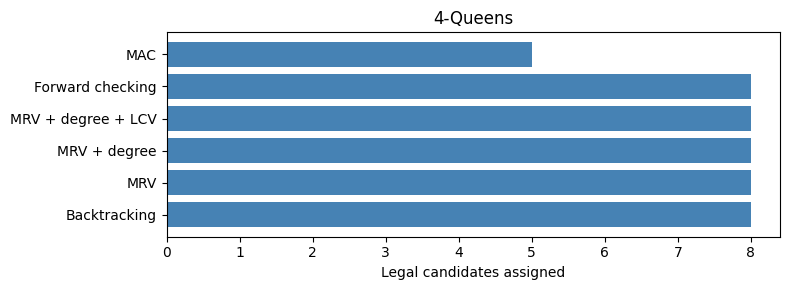


 Cryptarithmetic
Backtracking              {'calls': 68, 'attempts': 67, 'backtracks': 63, 'pruned': 0}
MRV                       {'calls': 5, 'attempts': 4, 'backtracks': 0, 'pruned': 0}
MRV + degree              {'calls': 5, 'attempts': 4, 'backtracks': 0, 'pruned': 0}
MRV + degree + LCV        {'calls': 5, 'attempts': 4, 'backtracks': 0, 'pruned': 0}
Forward checking          {'calls': 5, 'attempts': 4, 'backtracks': 0, 'pruned': 25}
MAC                       {'calls': 5, 'attempts': 4, 'backtracks': 0, 'pruned': 25}


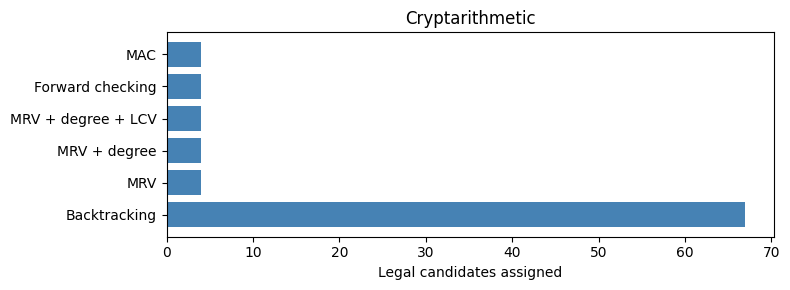

All solution-set, solver, and infeasibility checks passed.


In [ ]:
for name,results in [("Australia",map_results),("4-Queens",queen_results),("Cryptarithmetic",crypt_results)]:
    print("\n",name)
    for label,stats in results.items():print(f"{label:25s}",stats)
    fig,ax=plt.subplots(figsize=(8,3))
    ax.barh(list(results),[s["attempts"] for s in results.values()],color="steelblue")
    ax.set_xlabel("Legal candidates assigned");ax.set_title(name);plt.tight_layout();plt.show()
for model,expected in [(map_csp,18),(queens,2),(crypt,1)]:
    all_answers,checked=enumerate_csp(model)
    assert len(all_answers)==expected
    for label,opts in CONFIGS:
        a,s,_=solve(model,**opts)
        assert model.valid(a)
        assert any(a==b for b in all_answers)
# An infeasible version of the map checks sound failure behavior.
two_colors=BinaryCSP({x:colors[:2] for x in states},map_edges,not_equal)
for label,opts in CONFIGS:
    assert solve(two_colors,**opts)[0] is None
print("All solution-set, solver, and infeasibility checks passed.")
